# College Majors 2026: Model 2, Random Forest
## Predicting 4-year earnings of bachelor's programs

**Task (regression):** predict `target_log_earnings_4yr`, the log of a program's median earnings 4 years after completion.

**Why a random forest after Ridge?** Ridge can only fit straight-line effects, and it under-predicted the highest earners.
A random forest is built from decision trees, so it can capture **nonlinear effects and interactions**, for example
"a top field *and* a highly selective school pays more than either one alone".

This notebook re-fits Ridge (Model 1) in a few seconds so both models sit in one comparison table. Both use the
**same preprocessing pipeline**, the **same school-grouped train/test split** and the **same cross-validation folds**, so the comparison is fair.

> **To run:** put `bachelors_model_ready.csv` (made by the data-prep notebook) next to this notebook, then *Run All*.
> Tuning takes about **5–10 minutes** on a laptop.

## 0. Setup

In [2]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import GroupKFold, GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50, "display.width", 200)
%matplotlib inline

RANDOM_STATE = 42
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID, BG = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW = PALETTE[:4]
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": BG, "axes.facecolor": BG,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "xtick.color": INK2, "ytick.color": INK2, "font.size": 10,
})
def show(fig, name):
    fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, name), bbox_inches="tight"); plt.show()

## 1. Load the model-ready data and define features

In [3]:
df = pd.read_csv("bachelors_model_ready.csv", dtype={"opeid6": str, "cip_code_4digit": str})

NUMERIC = [
    "log_awards_avg", "is_main_campus", "outcomes_shared_across_campuses",
    "log_enrollment", "institution_tuition_in_state_usd", "tuition_out_minus_in",
    "institution_admission_rate", "admission_rate_missing", "institution_avg_sat", "sat_missing",
    "institution_is_hbcu", "institution_latitude", "institution_longitude",
    "national_median_earnings_4yr_usd",
    "linked_occupations_count", "occupation_median_wage_2024_usd", "occupation_growth_pct_2024_34",
    "occupation_growth_pct_max", "log_occ_employment",
    "occupations_using_ai_software", "ai_software_occupation_share", "expert_system_occupation_share",
    "ai_tools_max_per_occupation", "hot_technologies_mean_per_occupation", "any_ai_occupation",
]
CATEGORICAL = ["institution_control", "institution_region", "cip_family_title",
               "online", "selectivity", "occupation_typical_entry_education"]
FEATURES = NUMERIC + CATEGORICAL
TARGET = "target_log_earnings_4yr"
GROUP = "opeid6"

train = df[df.split == "train"].reset_index(drop=True)
test = df[df.split == "test"].reset_index(drop=True)
X_train, y_train, g_train = train[FEATURES], train[TARGET], train[GROUP]
X_test, y_test = test[FEATURES], test[TARGET]
print(f"Train: {X_train.shape}  |  Test: {X_test.shape}  |  Features: {len(FEATURES)}")

Train: (19932, 31)  |  Test: (5351, 31)  |  Features: 31


## 2. Shared preprocessing and cross-validation

- **Preprocessing** (inside every model's pipeline, fit on training folds only): median-impute and scale numbers; one-hot encode categories.
- **Cross-validation:** `GroupKFold(5)` grouped by institution, so a school is never in both the fitting and validation part of a fold.
  This matches how the test set was built.
- **Tuning metric:** R² on log earnings. Final results are also reported **in dollars**.

In [4]:
def make_preprocess():
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=30, sparse_output=False), CATEGORICAL),
    ])

cv = GroupKFold(n_splits=5)
results = {}          # test-set results for each model
cv_scores = {}        # best cross-validated R² for each model

## 3. Baseline: predict the field's national median

The simplest possible prediction, needing no model. Every model must beat it to be worth using.

In [5]:
def evaluate(name, pred_log):
    """Score predictions on the test set, both on log scale and in dollars."""
    actual = np.exp(y_test); pred = np.exp(pred_log)
    results[name] = {
        "R² (log)": r2_score(y_test, pred_log),
        "RMSE ($)": np.sqrt(mean_squared_error(actual, pred)),
        "MAE ($)": mean_absolute_error(actual, pred),
        "Median abs. % error": np.median(np.abs(pred - actual) / actual) * 100,
    }
    return pd.Series(results[name]).round(3)

base_pred = np.log(test["national_median_earnings_4yr_usd"])
evaluate("Baseline (national field median)", base_pred)

R² (log)                   0.566
RMSE ($)               12624.187
MAE ($)                 8760.366
Median abs. % error       10.413
dtype: float64

## 4. Model 1 (Ridge), re-fit for comparison

Same tuning as the Ridge notebook: 13 values of `alpha` from 0.001 to 1,000 with grouped 5-fold cross-validation.
Full details and charts are in `College_Majors_Model1_Ridge.ipynb`.

In [6]:
ridge = Pipeline([("prep", make_preprocess()), ("model", Ridge())])
ridge_grid = {"model__alpha": np.logspace(-3, 3, 13)}

t = time.time()
ridge_search = GridSearchCV(ridge, ridge_grid, cv=cv, scoring="r2", n_jobs=-1, return_train_score=True)
ridge_search.fit(X_train, y_train, groups=g_train)
print(f"Done in {time.time() - t:.0f}s | best alpha = {ridge_search.best_params_['model__alpha']:.3g} "
      f"| CV R² = {ridge_search.best_score_:.3f}")
cv_scores["Ridge regression"] = ridge_search.best_score_

Done in 8s | best alpha = 3.16 | CV R² = 0.753


In [7]:
evaluate("Ridge regression", ridge_search.predict(X_test))

R² (log)                   0.744
RMSE ($)               10005.070
MAE ($)                 7029.768
Median abs. % error        8.583
dtype: float64

## 5. Model 2: Random forest

**How it works:**
1. A **decision tree** splits the programs step by step with yes/no questions ("Is the field median above $75k?",
   "Is the admission rate below 25%?") and predicts the average earnings of the programs that end up in each final group (leaf).
2. A single deep tree memorizes the training data (overfits). A random forest grows **many trees**, each on a
   **random bootstrap sample of programs**, and at each split each tree considers only a **random subset of features**.
3. The forest's prediction is the **average of all trees**. Their individual errors partly cancel out, which reduces overfitting.

Because each tree asks questions in sequence, the forest picks up **interactions** (one feature matters more when another
is high) and **thresholds** without us building them by hand.

**Tuning** (randomized search, 8 combinations × 5 folds):
| Hyperparameter | Candidates | Why |
|---|---|---|
| `max_depth` | 12, 20, None | How deep each tree may grow; deeper = more complex patterns but more overfitting |
| `min_samples_leaf` | 1, 5, 20 | Minimum programs per leaf; larger values smooth predictions |
| `max_features` | 0.3, 0.6 | Share of features tried at each split; lower = more diverse trees |

`n_estimators` is fixed at 200: more trees never hurt accuracy, they only add run time, and 200 is enough to stabilize the average.
We use a **randomized** search (8 of the 18 combinations) because each forest takes several seconds to fit 5 times;
it covers the grid well at a fraction of the run time. **This cell takes about 5–10 minutes.**

In [8]:
rf = Pipeline([("prep", make_preprocess()),
               ("model", RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE))])
rf_grid = {"model__max_depth": [12, 20, None],
           "model__min_samples_leaf": [1, 5, 20],
           "model__max_features": [0.3, 0.6]}

t = time.time()
rf_search = RandomizedSearchCV(rf, rf_grid, n_iter=8, cv=cv, scoring="r2", random_state=RANDOM_STATE,
                               n_jobs=1, return_train_score=True)
rf_search.fit(X_train, y_train, groups=g_train)
print(f"Done in {time.time() - t:.0f}s | best = {rf_search.best_params_} | CV R² = {rf_search.best_score_:.3f}")
cv_scores["Random forest"] = rf_search.best_score_

cols = ["param_model__max_depth", "param_model__min_samples_leaf", "param_model__max_features",
        "mean_train_score", "mean_test_score"]
display(pd.DataFrame(rf_search.cv_results_)[cols].sort_values("mean_test_score", ascending=False)
        .rename(columns=lambda c: c.replace("param_model__", "").replace("mean_test_score", "CV R²")
                .replace("mean_train_score", "Train R²")).round(3).reset_index(drop=True))
evaluate("Random forest", rf_search.predict(X_test))

Done in 97s | best = {'model__min_samples_leaf': 5, 'model__max_features': 0.3, 'model__max_depth': None} | CV R² = 0.789


,max_depth,min_samples_leaf,max_features,Train R²,CV R²
0,None,5,0.3,0.888,0.789
1,None,5,0.6,0.900,0.788
2,None,1,0.6,0.971,0.787
3,12,1,0.6,0.880,0.782
4,12,1,0.3,0.867,0.781
5,12,5,0.3,0.842,0.781
6,12,20,0.6,0.817,0.775
7,20,20,0.3,0.815,0.773


R² (log)                  0.785
RMSE ($)               8922.597
MAE ($)                6243.425
Median abs. % error       7.584
dtype: float64

**Reading the tuning table:**
- **Best setting:** no depth limit, `min_samples_leaf = 5`, `max_features = 0.3` → **CV R² 0.789**.
- **Overfitting check:** with `min_samples_leaf = 1` the forest fits the training folds almost perfectly (Train R² 0.971) but does *not* do better on
  validation (0.787). Requiring at least 5 programs per leaf smooths predictions at no cost in accuracy.
- **Too much smoothing hurts:** `min_samples_leaf = 20` drops CV R² to ~0.774, so leaves that large miss real detail.
- **`max_features` 0.3 vs 0.6** makes almost no difference; 0.3 is chosen and is also faster.
- The train–CV gap (0.888 vs 0.789) is normal for a random forest; what matters is that **CV R² (0.789) and test R² (0.786) agree**, so it generalizes to unseen schools.

## 6. Model comparison so far (Section 4)

**Metrics (same for every model):**
- **R² (log scale):** share of variation in log earnings explained (1 = perfect). Matches what the models were trained on.
- **RMSE ($):** typical error in dollars; punishes big misses more.
- **MAE ($):** average absolute error in dollars; easiest to explain ("off by $X on average").
- **Median abs. % error:** typical error as a percentage of the program's actual earnings.

**CV R²** is from tuning on the training data; the other columns are from the untouched **test set** (360 institutions neither model has seen).

In [9]:
comp = pd.DataFrame(results).T
comp.insert(0, "CV R² (train)", pd.Series(cv_scores))
comp_fmt = comp.copy()
for c in ["RMSE ($)", "MAE ($)"]: comp_fmt[c] = comp[c].map("${:,.0f}".format)
comp_fmt["Median abs. % error"] = comp["Median abs. % error"].map("{:.1f}%".format)
for c in ["CV R² (train)", "R² (log)"]: comp_fmt[c] = comp[c].map(lambda v: "—" if pd.isna(v) else f"{v:.3f}")
comp_fmt

,CV R² (train),R² (log),RMSE ($),MAE ($),Median abs. % error
Baseline (national field median),—,0.566,"$12,624","$8,760",10.4%
Ridge regression,0.753,0.744,"$10,005","$7,030",8.6%
Random forest,0.789,0.785,"$8,923","$6,243",7.6%


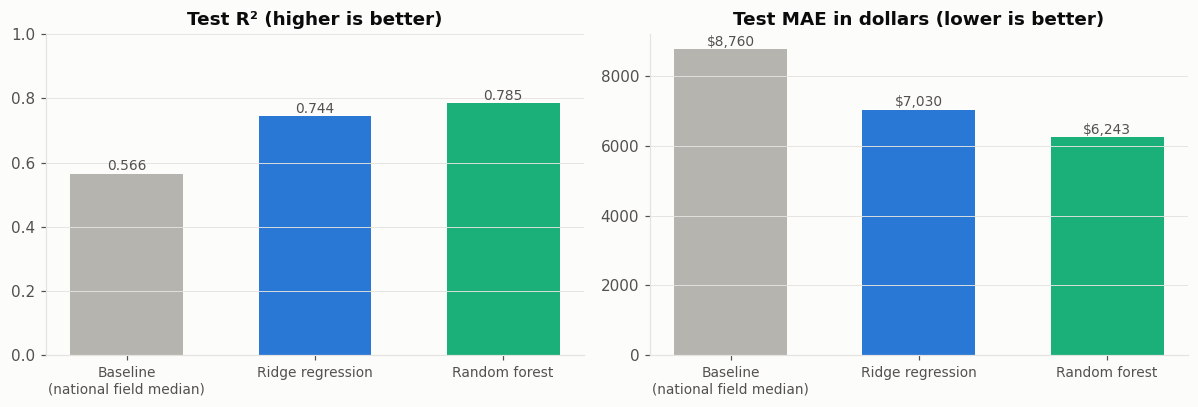

In [10]:
colors = ["#b5b4ae", BLUE, AQUA]
short = ["Baseline\n(national field median)", "Ridge regression", "Random forest"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
vals = comp["R² (log)"].values
axes[0].bar(short, vals, color=colors, width=0.6)
for x, v in enumerate(vals): axes[0].text(x, v + 0.01, f"{v:.3f}", ha="center", fontsize=9, color=INK2)
axes[0].set(title="Test R² (higher is better)", ylim=(0, 1)); axes[0].grid(axis="x", visible=False)
vals = comp["MAE ($)"].values
axes[1].bar(short, vals, color=colors, width=0.6)
for x, v in enumerate(vals): axes[1].text(x, v + 100, f"${v:,.0f}", ha="center", fontsize=9, color=INK2)
axes[1].set(title="Test MAE in dollars (lower is better)"); axes[1].grid(axis="x", visible=False)
for a in axes: a.tick_params(axis="x", labelsize=9)
show(fig, "m2_comparison_baseline_ridge_rf.png")

### 6.1 Random forest: predicted vs. actual

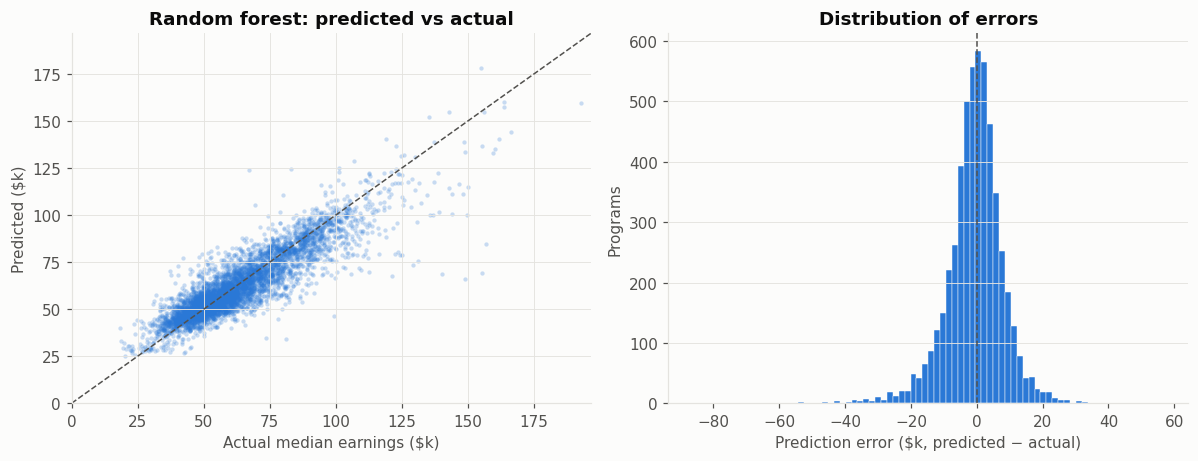

Ridge          within ±10%: 56%   within ±20%: 85%
Random forest  within ±10%: 61%   within ±20%: 88%


In [11]:
best_name, best = "Random forest", rf_search
pred = np.exp(best.predict(X_test)); actual = np.exp(y_test)
pred_ridge = np.exp(ridge_search.predict(X_test))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
axes[0].scatter(actual / 1000, pred / 1000, s=8, alpha=0.25, color=BLUE, linewidths=0)
lim = [0, max(actual.max(), pred.max()) / 1000 * 1.02]
axes[0].plot(lim, lim, color=INK2, linestyle="--", linewidth=1)
axes[0].set(xlim=lim, ylim=lim, xlabel="Actual median earnings ($k)", ylabel="Predicted ($k)",
            title=f"{best_name}: predicted vs actual")
err = (pred - actual) / 1000
axes[1].hist(err, bins=80, color=BLUE, edgecolor=BG, linewidth=0.3)
axes[1].axvline(0, color=INK2, linestyle="--", linewidth=1)
axes[1].set(xlabel="Prediction error ($k, predicted − actual)", ylabel="Programs", title="Distribution of errors")
axes[1].grid(axis="x", visible=False)
show(fig, "m2_rf_pred_vs_actual.png")
for name, p in [("Ridge", pred_ridge), ("Random forest", pred)]:
    pe = np.abs(p - actual) / actual
    print(f"{name:<14} within ±10%: {(pe <= 0.10).mean():.0%}   within ±20%: {(pe <= 0.20).mean():.0%}")

### 6.2 Did it fix Ridge's weak spot? Errors by earnings level

Ridge under-predicted the highest earners. Here we split the test programs by their **actual** earnings and compare the
average signed error (predicted − actual) of both models in each group. Zero = no systematic bias; negative = predicting too low.

,Programs,Ridge avg error,RF avg error
band,,,
<$40k,333,"$7,232","$6,438"
$40–60k,2562,"$1,890","$1,645"
$60–80k,1495,"$-1,643","$-2,054"
$80–100k,703,"$-4,423","$-4,626"
$100–150k,245,"$-13,408","$-12,547"
$150k+,13,"$-39,795","$-25,321"


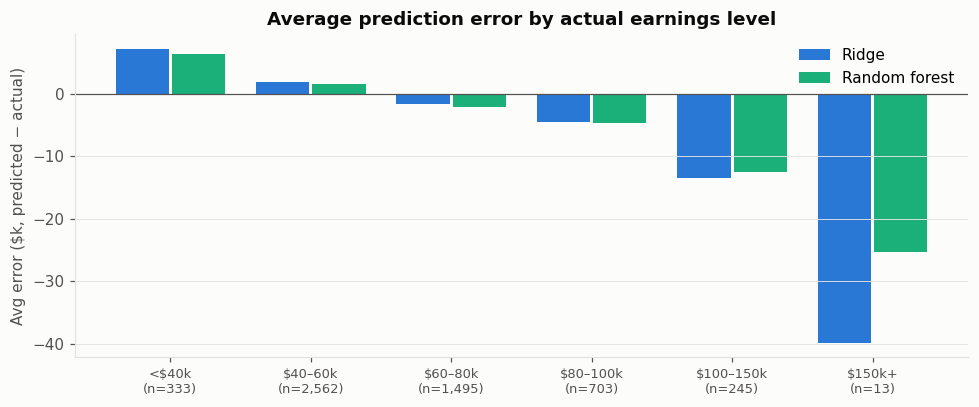

In [12]:
bands = pd.cut(actual, [0, 40e3, 60e3, 80e3, 100e3, 150e3, np.inf],
               labels=["<$40k", "$40–60k", "$60–80k", "$80–100k", "$100–150k", "$150k+"])
bias = pd.DataFrame({"band": bands, "Ridge": pred_ridge - actual, "Random forest": pred - actual})
summary_band = bias.groupby("band", observed=True).agg(programs=("Ridge", "size"),
                                                        ridge_bias=("Ridge", "mean"), rf_bias=("Random forest", "mean"))
display((summary_band.assign(ridge_bias=lambda d: d.ridge_bias.map("${:,.0f}".format),
                             rf_bias=lambda d: d.rf_bias.map("${:,.0f}".format))
         .rename(columns={"programs": "Programs", "ridge_bias": "Ridge avg error", "rf_bias": "RF avg error"})))

fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(summary_band)); w = 0.38
ax.bar(x - w/2 - 0.01, summary_band.ridge_bias / 1000, w, color=BLUE, label="Ridge")
ax.bar(x + w/2 + 0.01, summary_band.rf_bias / 1000, w, color=AQUA, label="Random forest")
ax.axhline(0, color=INK2, linewidth=0.8)
ax.set_xticks(x, [f"{b}\n(n={n:,})" for b, n in zip(summary_band.index, summary_band.programs)], fontsize=8.5)
ax.set(ylabel="Avg error ($k, predicted − actual)", title="Average prediction error by actual earnings level")
ax.legend(frameon=False); ax.grid(axis="x", visible=False)
show(fig, "m2_error_by_earnings_band.png")

**What this shows:**
- The random forest is **more accurate overall**, but both models share the same pattern: they **over-predict low earners and under-predict high
  earners**. This is "regression toward the middle": extreme programs are rare, so predictions get pulled toward typical values.
- The forest **reduces the miss for the $150k+ programs** (average error about −$27k vs −$40k for Ridge), but only 13 test programs are in that group,
  so treat it as a hint, not a firm result.
- For the $100–150k group the two models are similar (about −$13k vs −$13k), so the high-earner problem is **only partly** fixed.
  Gradient boosting (Model 3) is the natural next try.

### 6.3 Which features does the random forest rely on? (permutation importance)

**Permutation importance:** shuffle one feature's values in the test set and measure how much R² drops.
A big drop means the model relies on that feature. It works the same way for any model, so you can compare it directly with Ridge's chart.

Computed in 9s


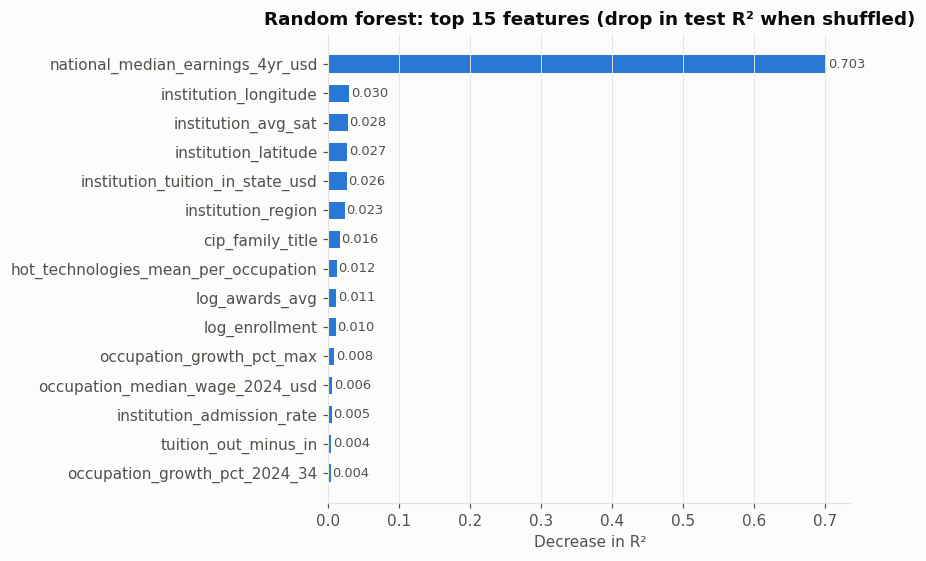

In [14]:
t = time.time()
pi = permutation_importance(best, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE, scoring="r2", n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False)
print(f"Computed in {time.time() - t:.0f}s")

top = imp.head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh(top.index, top.values, color=BLUE, height=0.6)
for i, v in enumerate(top.values): ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8.5, color=INK2)
ax.set(title=f"{best_name}: top 15 features (drop in test R² when shuffled)", xlabel="Decrease in R²")
ax.grid(axis="y", visible=False)
show(fig, "m2_rf_permutation_importance.png")

## 7. Summary

In [15]:
b = comp.loc["Baseline (national field median)"]; r = comp.loc["Ridge regression"]; m = comp.loc[best_name]
print(f"Random forest vs Ridge:  R² {m['R² (log)']:.3f} vs {r['R² (log)']:.3f}  |  "
      f"MAE ${m['MAE ($)']:,.0f} vs ${r['MAE ($)']:,.0f}")
print(f"  Test R² {m['R² (log)']:.3f} vs baseline {b['R² (log)']:.3f}  "
      f"(+{m['R² (log)'] - b['R² (log)']:.3f})")
print(f"  MAE ${m['MAE ($)']:,.0f} vs baseline ${b['MAE ($)']:,.0f}  "
      f"({(1 - m['MAE ($)'] / b['MAE ($)']):.0%} smaller)")
print(f"  Top 5 features: {', '.join(imp.index[:5])}")

Random forest vs Ridge:  R² 0.785 vs 0.744  |  MAE $6,243 vs $7,030
  Test R² 0.785 vs baseline 0.566  (+0.219)
  MAE $6,243 vs baseline $8,760  (29% smaller)
  Top 5 features: national_median_earnings_4yr_usd, institution_longitude, institution_avg_sat, institution_latitude, institution_tuition_in_state_usd


### Takeaways
- **The random forest beats Ridge on every metric:** test R² **0.786 vs 0.744**, average error (MAE) **$6,232 vs $7,030** (11% smaller),
  and typical error **7.6% vs 8.6%**. Against the baseline, the MAE is 29% smaller.
- **More programs predicted closely:** 61% within ±10% (Ridge 56%) and 88% within ±20% (Ridge 85%).
- **Why it does better:** trees capture **nonlinear effects and interactions** that a straight-line model can't, such as location and school quality
  mattering differently for different fields.
- **It generalizes:** CV R² (0.789) and test R² (0.786) match, so the gain is real on schools the model has never seen.
- **Feature use differs from Ridge:** after the field median, the forest relies on **location (latitude/longitude), SAT and tuition**, while Ridge leaned on
  region dummies. Precise location lets the forest pick up local wage levels (big metro areas) that broad regions miss.
- **Remaining weakness:** the highest earners are still under-predicted, although less than with Ridge.

**Next step:** Model 3, gradient boosting, with the same pipeline, split and metrics.